# EDA of simulated normal behaviour 

Explores `data/normal.parquet` (28 days, 12 cells, 1-minute steps, seed 42), made with `cellpulse-simulate`.
Goal: check the simulator produces realistic, consistent normal data before faults and detectors are built on top of it.

In [43]:
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["figure.dpi"] = 60

df = pd.read_parquet("../data/normal.parquet")

### 1. Table checks

In [44]:
df.head()

,cell_id,observed_at,dl_throughput_mbps,ul_throughput_mbps,prb_utilisation_pct,latency_ms,active_ues,call_drop_rate_pct,rrc_success_rate_pct,sinr_db
0,site-a/cell-001,2026-01-05 00:00:00+00:00,73.595600,37.494394,28.878739,5.250650,43,0.334262,99.675481,14.370884
1,site-a/cell-001,2026-01-05 00:01:00+00:00,81.406600,43.289388,26.038666,5.177451,39,0.395162,99.622987,13.788057
2,site-a/cell-001,2026-01-05 00:02:00+00:00,80.818905,39.664552,23.590846,5.095570,36,0.339399,99.434362,12.766700
3,site-a/cell-001,2026-01-05 00:03:00+00:00,80.396222,42.364433,24.250731,5.038890,36,0.310371,99.464095,13.116615
4,site-a/cell-001,2026-01-05 00:04:00+00:00,79.275120,39.152170,23.913379,5.157021,36,0.287297,99.462679,12.886029


In [45]:
df.shape

(483840, 10)

In [46]:
df.dtypes

cell_id                                 str
observed_at             datetime64[us, UTC]
dl_throughput_mbps                  float64
ul_throughput_mbps                  float64
prb_utilisation_pct                 float64
latency_ms                          float64
active_ues                           uint32
call_drop_rate_pct                  float64
rrc_success_rate_pct                float64
sinr_db                             float64
dtype: object

In [47]:
df.isna().sum()

cell_id                 0
observed_at             0
dl_throughput_mbps      0
ul_throughput_mbps      0
prb_utilisation_pct     0
latency_ms              0
active_ues              0
call_drop_rate_pct      0
rrc_success_rate_pct    0
sinr_db                 0
dtype: int64

In [48]:
df["cell_id"].value_counts()

cell_id
site-a/cell-001    40320
site-a/cell-002    40320
site-a/cell-003    40320
site-a/cell-004    40320
site-b/cell-001    40320
site-b/cell-002    40320
site-b/cell-003    40320
site-b/cell-004    40320
site-c/cell-001    40320
site-c/cell-002    40320
site-c/cell-003    40320
site-c/cell-004    40320
Name: count, dtype: int64

In [49]:
df["observed_at"].min(), df["observed_at"].max()

(Timestamp('2026-01-05 00:00:00+0000', tz='UTC'),
 Timestamp('2026-02-01 23:59:00+0000', tz='UTC'))

In [50]:
df.groupby("cell_id")["observed_at"].diff().value_counts(dropna=False)

observed_at
0 days 00:01:00    483828
NaT                    12
Name: count, dtype: int64

**Findings, section 1:**
- Rows and columns: 483,840 rows × 10 columns
- Missing values: 0 missing values 
- Rows per cell: 40,320 for every cell = 1,440 × 28
- Time range: Mon 5 Jan 2026 00:00 UTC to Sun 1 Feb 2026 23:59 UTC, exactly 4 full weeks
- Gaps between time steps (and why there are some NaT): 483,828 gaps of exactly 1 minute and 12 NaT

### 2. Value ranges vs the expected range
| KPI | Expected range |
|---|---|
| prb_utilisation_pct | typical 50–70 %; above 80 % approaching capacity |
| dl_throughput_mbps | target 100 Mbps; falls as the cell gets busier |
| ul_throughput_mbps | target 50 Mbps; lower than download |
| latency_ms | about 1–20 ms |
| call_drop_rate_pct | below 2 % |
| rrc_success_rate_pct | above 98 % |
| sinr_db | about −10 to 30+ dB |
| active_ues | no universal range; low at night, high at peak |

In [51]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
dl_throughput_mbps,483840.0,75.17,12.38,31.43,67.34,76.37,85.07,106.39
ul_throughput_mbps,483840.0,37.59,6.19,15.67,33.66,38.19,42.54,53.30
prb_utilisation_pct,483840.0,32.93,13.73,4.92,21.42,31.48,41.51,83.16
latency_ms,483840.0,5.40,0.75,4.31,5.01,5.17,5.45,12.69
active_ues,483840.0,67.28,35.87,0.00,39.00,61.00,88.00,209.00
call_drop_rate_pct,483840.0,0.30,0.05,0.07,0.27,0.30,0.33,0.54
rrc_success_rate_pct,483840.0,99.50,0.10,99.04,99.43,99.50,99.57,99.97
sinr_db,483840.0,14.93,2.61,4.90,13.13,14.77,16.60,26.08


**Findings, section 2:**
- KPIs outside (or at the edge of) their range, and is that a problem?

1. Throughput above 100 / 50 Mbps: The formula can never exceed 100 but the ±3% measurement noise is due to the fact noise is applied AFTER the formula. Which is why max excedes our expected 100mbps. 

2. PRB above 80 %: only 29 of 483,840 rows. These are the busiest evening minutes, when the drifting noise pushes an already busy cell higher. This is the same reason as why Throughput has an increases max. 

3. 0 users at night: the night baseline is 0.12 but each cell is multipled by busyness and then it is rounded which gives 0 users. It happens in only 30 rows with ≤3 users because for it to round up to 0 busyness needs to be around 0.8–1.2.    


### 3. Daily and weekly pattern

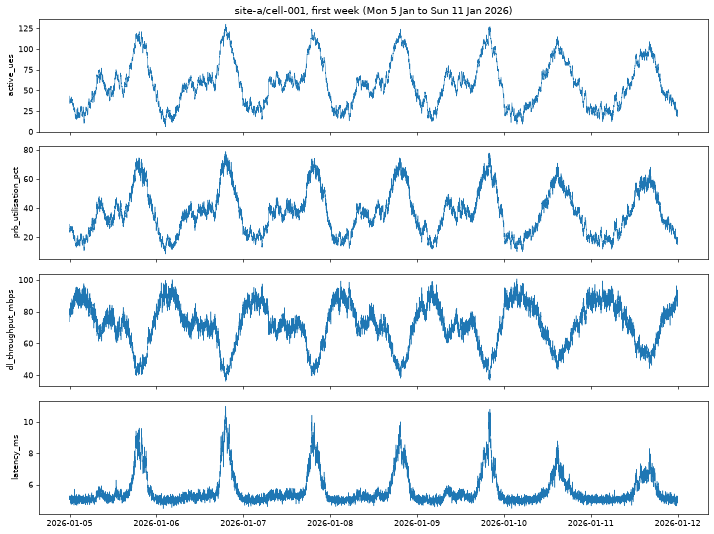

In [52]:
cell = df[df["cell_id"] == "site-a/cell-001"]
week = cell[cell["observed_at"] < "2026-01-12"]

kpis = ["active_ues", "prb_utilisation_pct", "dl_throughput_mbps", "latency_ms"]
fig, axes = plt.subplots(len(kpis), 1, figsize=(12, 9), sharex=True)
for ax, kpi in zip(axes, kpis, strict=True):
    ax.plot(week["observed_at"], week[kpi], linewidth=0.6)
    ax.set_ylabel(kpi)
axes[0].set_title("site-a/cell-001, first week (Mon 5 Jan to Sun 11 Jan 2026)")
fig.tight_layout()
plt.show()

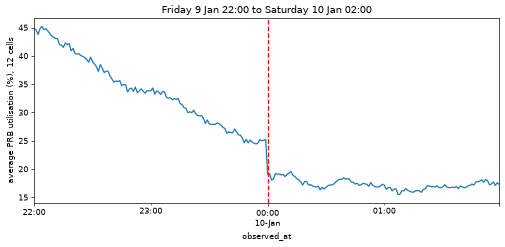

In [53]:
window = df[(df["observed_at"] >= "2026-01-09 22:00") & (df["observed_at"] < "2026-01-10 02:00")]
avg = window.groupby("observed_at")["prb_utilisation_pct"].mean()

ax = avg.plot(figsize=(10, 4))
ax.axvline(pd.Timestamp("2026-01-10 00:00", tz="UTC"), color="red", linestyle="--")
ax.set_ylabel("average PRB utilisation (%), 12 cells")
ax.set_title("Friday 9 Jan 22:00 to Saturday 10 Jan 02:00")
plt.show()

/tmp/ipykernel_22545/1117197160.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  weekend = (df["observed_at"].dt.dayofweek >= 5).rename("weekend")


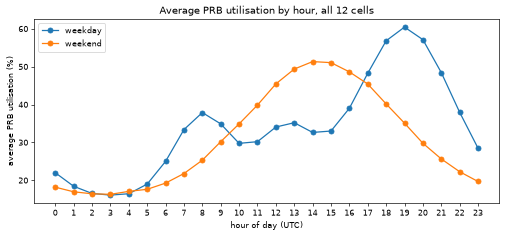

In [54]:
hour = df["observed_at"].dt.hour.rename("hour")
weekend = (df["observed_at"].dt.dayofweek >= 5).rename("weekend")

hourly = df.groupby([weekend, hour])["prb_utilisation_pct"].mean().unstack("weekend")
hourly.columns = ["weekday", "weekend"]

ax = hourly.plot(figsize=(10, 4), marker="o")
ax.set_xlabel("hour of day (UTC)")
ax.set_ylabel("average PRB utilisation (%)")
ax.set_title("Average PRB utilisation by hour, all 12 cells")
ax.set_xticks(range(24))
plt.show()

**Findings, section 3:**
- Does each KPI move the way the design says (direction and shape)? 
Yes. Users and PRB rise and fall together, throughput is their mirror image (high at night, low at peak), and latency stays flat at ~5 ms and only spikes at the evening peaks.

- Weekday: where are the peaks, how big are they, and do they match the bumps choosen (08:30, 13:00, 19:30)?
Three peaks. Morning around 08–09 (avg PRB ~38 %), lunch around 13 (~35 %), and the big evening peak at 19 (~60 %). They match the bumps (08:30, 13:00, 19:30), and the evening is the largest as designed.

- Weekend vs weekday: The weekend has one broud and smooth peak as expected. However looking at the second graph the change from weekeday and weekend is not smooth. This is a little concerning because the sudden dip would probably lead to a false alarm every time there is a change from the weekend to the weekday and vis versa. 